In [1]:
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from glob import glob as gb
import os
import sys
import warnings
warnings.filterwarnings("ignore")

/home/jap/miniconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [7]:
############################
var='tas'#sys.argv[1] #'pr' #'tas'
tri,per='jja','m7' #sys.argv[2] #'m1' 
#tri,per='djf','m1'
print(var,per)

tas m7


In [2]:
import geopandas as gpd

In [91]:
shp_peru=gpd.read_file('shape/peru.shp')
shp_suda=gpd.read_file('shape/suda.shp')

In [5]:
plt.rcParams.update({'font.size': 12})

In [6]:
# FUNCIONES #########################
def polinom(d,var):
    coef=d.polyfit(dim='time', deg=4, full=True) # genera los coeficientes del polinomio 4°
    s_poli=xr.polyval(coord=d.time, coeffs=coef['%s_polyfit_coefficients'%var]) # Serie polinomica
    residuo0=((d[var]/s_poli)*100)-100 # residuo = ε(t)
    prom_PR=s_poli.sel(time=slice('1981','2010')).mean(dim='time') #promedio del Periodo de Referencia
    if 't' in var: delta0=s_poli-((s_poli/s_poli)*prom_PR) # delta = ΔT
    else: delta0=((s_poli/prom_PR)*100)-100 # delta = ΔP
    return delta0,residuo0  

In [27]:
########## PARTE 1 #########
j=0; k=0
for exp in ['126','245','370','585'][:]:
    files=gb('data/%s/%s_%s*%s*.nc'%(tri,per,var,exp))
    i=0
    print(exp)
    for file in files[:]:  
        # print(file)
        ds=xr.open_dataset(file)
        delta,residuo=polinom(ds,var)    
        if i==0: delta2=delta
        else: delta2=xr.concat([delta,delta2],dim='time')                
        if j==0: delta3=delta; residuo4=residuo
        else: 
            delta3=xr.concat([delta,delta3],dim='time')
            residuo4=xr.concat([residuo,residuo4],dim='time')
        j=j+1;k=k+1;i=i+1
        #
    delta21=delta2.sortby('time',ascending=True)
    var_delta21=delta21.groupby('time.year').var() # var de todos los modelos en un escenario
    prom_delta21=delta21.groupby('time.year').mean() # prom de todos los modelos en un escenario
    if '126' in exp: lst_var_mdl=var_delta21; lst_prom_mdl=prom_delta21
    else: 
        lst_var_mdl=xr.concat([lst_var_mdl,var_delta21],dim='year')
        lst_prom_mdl=xr.concat([lst_prom_mdl,prom_delta21],dim='year')

126
245
370
585


In [33]:
########## PARTE 2 #########        
var_mdl_2=lst_var_mdl.sortby('year',ascending=True)
prom_mdl_2=lst_prom_mdl.sortby('year',ascending=True)
delta31=delta3.sortby('time',ascending=True)
residuo41=residuo4.sortby('time',ascending=True)

In [77]:
#
G0=delta31.groupby('time.year').mean() # promedio de todos los modelos en todos los escenarios
G0['year']=pd.date_range('1981', freq='12M', periods=len(G0.year))
G0 = G0.rename({'year': 'time'})
#incertidumbre de escenarios
SU0=prom_mdl_2.groupby('year').var() # Scenario Uncertainty "SU" desde el var
SU0['year']=pd.date_range('1981', freq='12M', periods=len(SU0.year))
SU0 = SU0.rename({'year': 'time'})
#incertidumbre de modelos 
MU0=var_mdl_2.groupby('year').mean() # Model Uncertainty  "MU"
MU0['year']=pd.date_range('1981', freq='12M', periods=len(MU0.year))
MU0 = MU0.rename({'year': 'time'})

In [78]:
########## PARTE 3 ######### 
year_c=2010; l=0
for ktime in range(len(ds['time'])-30):
    y_i=residuo41['time.year'][ktime*k].values; yi=str(y_i.tolist())
    y_f=(residuo41['time.year'][ktime*k].values)+29; yf=str(y_f.tolist())
    residuo42=residuo41.sel(time=slice(yi,yf))
    residuo43_std=residuo42.std(dim='time')
    residuo43_var=residuo42.var(dim='time')
    year_c=year_c+1
    #expande dimensiones: dim=tiempo
    time_d = pd.date_range('%d'%year_c, freq='1Y', periods=1)
    time_ds = xr.DataArray(time_d, [('time', time_d)])
    residuo44_std = residuo43_std.expand_dims(time=time_ds)
    residuo44_var = residuo43_var.expand_dims(time=time_ds)
    if l==0:         
        residuo_45_std=residuo44_std
        residuo_45_var=residuo44_var
    else: 
        residuo_45_std=xr.concat([residuo44_std,residuo_45_std], dim='time')
        residuo_45_var=xr.concat([residuo44_var,residuo_45_var], dim='time')
    l=l+1

In [79]:
########## PARTE 4 ######### 
VI0=residuo_45_std.sortby('time',ascending=True)
#VI0=residuo_45_var.sortby('time',ascending=True)
VI0['time']=pd.date_range('2011', freq='12M', periods=len(VI0.time))
VI1=VI0.rolling(time=10, center=False).mean()
# seleccionar el mismo periodo de datos
VI=VI1.sel(time=slice('2020','2100'))

In [80]:
G=G0.sel(time=slice('2020','2100'))
SU=SU0.sel(time=slice('2020','2100'))
#SU_std=SU_std0.sel(time=slice('2020','2100'))
MU=MU0.sel(time=slice('2020','2100'))

In [82]:
# calculo de STN y TOE
TU=VI+MU+SU
STN=G/(TU)**0.5
TOE=G/(VI)**0.5
########## PARTE 5 ######### 
os.system('mkdir -p out')
TOE.to_netcdf('out/toe_%s_%s.nc'%(var,per))
MU.to_netcdf('out/Tmu_%s_%s.nc'%(var,per))
SU.to_netcdf('out/Tsu_%s_%s.nc'%(var,per))
VI.to_netcdf('out/Tvi_%s_%s.nc'%(var,per))
# print('done')

In [83]:
############################
var='tas'#sys.argv[1] #'pr' #'tas'
#tri,per='jja','m7' #sys.argv[2] #'m1' 
tri,per='jja','m7'
ofile='out/toe_%s_%s.nc'%(var,per)
TOE=xr.open_dataset(ofile)['__xarray_dataarray_variable__']

In [84]:
t_TOE=TOE*np.nan
tpr=2020

In [85]:
for tpru in range(len(TOE.time)):
    t_TOE=t_TOE.where(~((TOE<tpr)&(TOE['time.year']==tpr)),tpr)
    tpr=tpr+1

In [86]:
if var=='pr':
    for umbr in [-1, 1]:
        TOE_umbr=TOE[0]*0
        for t in range(len(TOE.time)):
            if umbr==-1:
                TOE_umbr=TOE_umbr.where(~((TOE[t]<umbr)&(TOE_umbr<=0)),t_TOE[t])
                TOE_umbralnegativo_pr=TOE_umbr
            else:
                TOE_umbr=TOE_umbr.where(~((TOE[t]>umbr)&(TOE_umbr<=0)),t_TOE[t])
                TOE_umbralpositivo_pr=TOE_umbr
    TOE_1=TOE_umbralnegativo_pr.where(~(TOE_umbralnegativo_pr==0),np.nan)
    TOE_2=TOE_umbralpositivo_pr.where(~(TOE_umbralpositivo_pr==0),np.nan)
else:
    for umbr in [1, 2]:
        TOE_umbr=TOE[0]*0
        for t in range(len(TOE.time)):
            TOE_umbr=TOE_umbr.where(~((TOE[t]>umbr)&(TOE_umbr<=0)),t_TOE[t])
            if umbr==1: TOE_u1_tas=TOE_umbr
            else: TOE_u2_tas=TOE_umbr
    TOE_1=TOE_u1_tas.where(~(TOE_u1_tas==0),np.nan)
    TOE_2=TOE_u2_tas.where(~(TOE_u2_tas==0),np.nan)

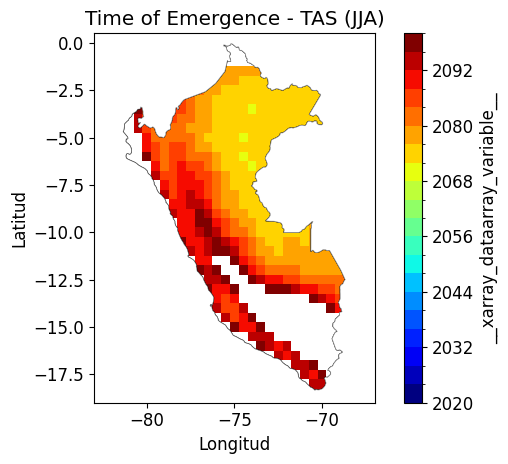

In [108]:
fig,ax=plt.subplots()
TOE_2.plot(ax=ax,levels=np.arange(2020,2104,4),cmap='jet')
# --- LIMITES GEOGRAFICOS ---
# Ajusta los limites de longitud (x) y latitud (y) segun tu region de interes
# Ejemplo: Peru y region andina
ax.set_xlim(-83, -67)   # Longitud: de -85°O a -65°O
ax.set_ylim(-19, 0.5)     # Latitud: de -20°S a 5°N
# --- SHAPEFILES ---
shp_peru.plot(ax=ax, fc='none', edgecolor='black', linewidth=0.8)
shp_suda.plot(ax=ax, fc='white', edgecolor='gray', linewidth=0.3)
# --- ETIQUETAS ---
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_title('Time of Emergence - %s (%s)' % (var.upper(), tri.upper()))
plt.tight_layout()

<Axes: title={'center': 'time = 2100-01-31'}, xlabel='lon', ylabel='lat'>

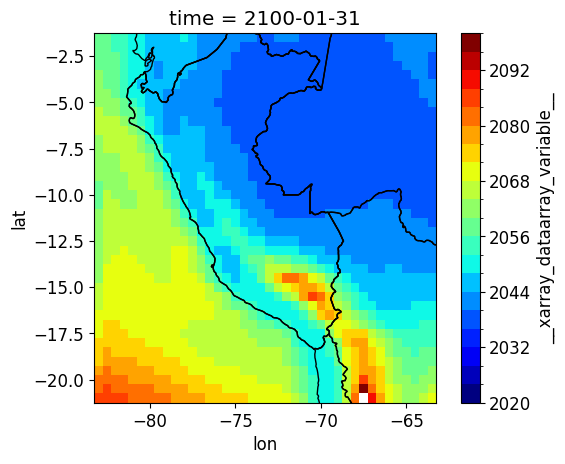

In [92]:
fig,ax=plt.subplots()
TOE_1.plot(ax=ax,levels=np.arange(2020,2104,4),cmap='jet')
shp_peru.plot(ax=ax,fc='none')
shp_suda.plot(ax=ax,fc='none')

### FRACCION

In [88]:
varn='__xarray_dataarray_variable__'
mu_perc=xr.open_dataset('out/Tmu_%s_%s.nc'%(var,per))[varn].sel(lat=slice(-17,-12),lon=slice(-75,-70)).mean(dim=['lon','lat'])
su_perc=xr.open_dataset('out/Tsu_%s_%s.nc'%(var,per))[varn].sel(lat=slice(-17,-12),lon=slice(-75,-70)).mean(dim=['lon','lat'])
vi_perc=xr.open_dataset('out/Tvi_%s_%s.nc'%(var,per))[varn].sel(lat=slice(-17,-12),lon=slice(-75,-70)).mean(dim=['lon','lat'])

In [89]:
total=vi_perc+su_perc+mu_perc
pvi=vi_perc*100/total
psu=su_perc*100/total
pmu=mu_perc*100/total

(2020.0, 2100.0)

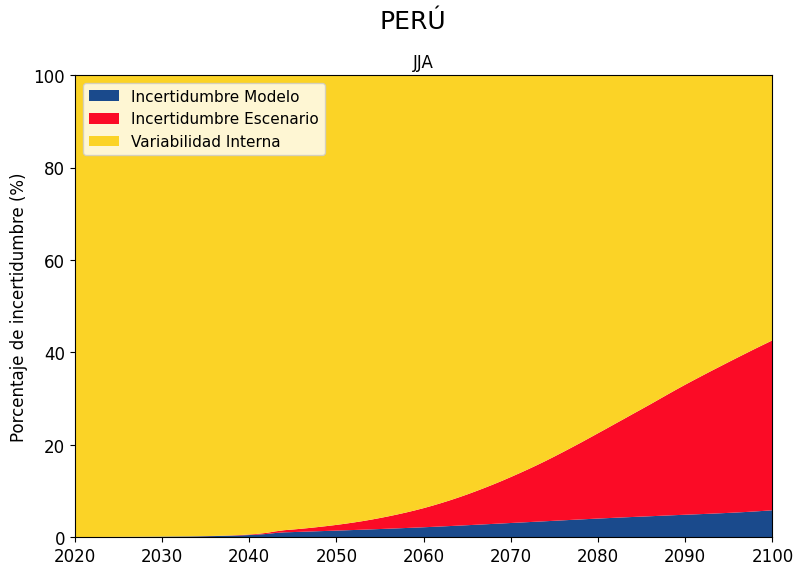

In [90]:
# INCERTIDUMBRE EN FRACCION
color_m = ['#1a4a8c', '#fb0b26', '#fbd326']
label=['Incertidumbre Modelo','Incertidumbre Escenario','Variabilidad Interna']
fig, ax = plt.subplots(1,1, figsize=(9, 6), sharey=True, sharex=True)
fig.subplots_adjust(hspace=0.17, wspace=0.05)
fig.suptitle('PERÚ', y=0.99, fontsize=18)
# PLOT
ax.stackplot(range(2020, 2101), pmu, psu, pvi, labels=label, colors=color_m)
ax.set_title(tri.upper(), fontsize=12)
# 
ax.set_ylabel('Porcentaje de incertidumbre (%)')
ax.legend(loc='upper left', fontsize=11)
ax.margins(0, 0)
ax.set_xlim(2020, 2100)
#plt.savefig('Fraccion_incertidumbre_peru_%s_interpol.jpg'%(var), dpi=400, bbox_inches='tight')